In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
from sklearn.datasets import fetch_california_housing

In [3]:
housing = fetch_california_housing(as_frame=True)
housing.target

0        4.526
1        3.585
2        3.521
3        3.413
4        3.422
         ...  
20635    0.781
20636    0.771
20637    0.923
20638    0.847
20639    0.894
Name: MedHouseVal, Length: 20640, dtype: float64

In [4]:
print(housing.DESCR)

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib:
https://lib.stat.cmu.edu/datasets/houses.zip

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per census
block group. A block g

In [5]:
housing.data.to_csv('CaliforniaHousing.csv', index=False)
housing.target.to_csv('CaliforniaHousingTarget.csv', index=False)


Text(0.5, 0, 'Median House Value $100k')

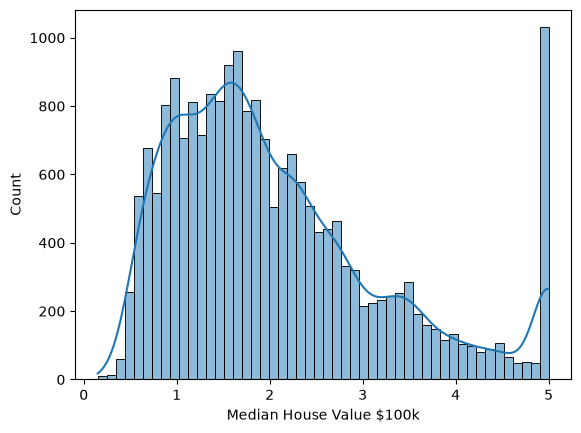

In [6]:
p = sns.histplot(housing.target,bins=50,kde=True)
p.set_xlabel('Median House Value $100k')



In [7]:
#check for any nulls in the data
housing.data.columns = housing.data.columns.str.lower()
housing.data.isnull().sum()

medinc        0
houseage      0
averooms      0
avebedrms     0
population    0
aveoccup      0
latitude      0
longitude     0
dtype: int64

In [8]:
housing.data.describe()

,medinc,houseage,averooms,avebedrms,population,aveoccup,latitude,longitude
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000


In [15]:
n = len(housing.data)
int_val = int(n*0.2)
int_test = int(n*0.2)
int_train = int(n-(int_val+int_test))

#generate random index
np.random.seed(2)
idx = np.arange(n)
np.random.shuffle(idx)

#apply random index
df_train = housing.data.iloc[idx[:int_train]]
df_val = housing.data.iloc[idx[int_train:int_train+int_val]]
df_test = housing.data.iloc[idx[int_train+int_val:]]

y_train = housing.target.iloc[idx[:int_train]]
y_val = housing.target.iloc[idx[int_train:int_train+int_val]]
y_test = housing.target.iloc[idx[int_train+int_val:]]

df_train.reset_index(inplace=True)
df_val.reset_index(inplace=True)
df_test.reset_index(inplace=True)

int_val,int_test,int_train, int_val+int_test+int_train,n

(4128, 4128, 12384, 20640, 20640)

In [16]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [24]:
flds = ['medinc','houseage','averooms']#,'avebedrms','population','aveoccup']
X_train = df_train[flds].values
w0, w = train_linear_regression(X_train, y_train)

In [25]:
y_pred = w0+X_train.dot(w)

<Axes: xlabel='MedHouseVal', ylabel='Count'>

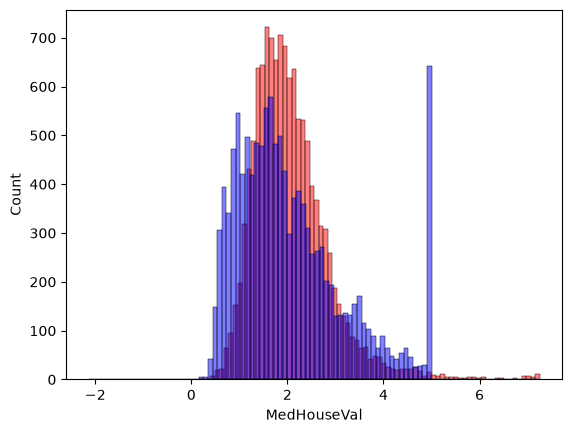

In [26]:
sns.histplot(y_pred, color='red', alpha=0.5, bins=100)
sns.histplot(y_train, color='blue', alpha=0.5, bins=50)

In [82]:
def rmse(y_pred, y):
    rm = np.sqrt(((y_pred-y)**2).mean())
    return rm

def rmse_baseline(y_pred, y):
    y_mean = np.full(len(y),y.mean())
    rm = np.sqrt(((y_pred-y_mean)**2).mean())
    return rm

In [83]:
print(f'Baseline RMSE:{rmse_baseline(y_pred,y_train)},Modelled RMSEL{rmse(y_pred,y_train)}')

Baseline RMSE:0.8940368216914215,Modelled RMSEL0.7370104754500834


In [34]:
flds = ['medinc','houseage','averooms','avebedrms','population','aveoccup']
X_train = df_train[flds].values
w0, w = train_linear_regression(X_train, y_train)
y_pred = w0+X_train.dot(w)

<Axes: xlabel='MedHouseVal', ylabel='Count'>

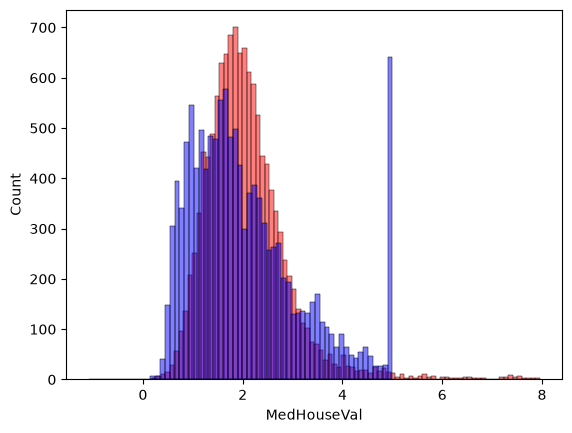

In [35]:
sns.histplot(y_pred, color='red', alpha=0.5, bins=100)
sns.histplot(y_train, color='blue', alpha=0.5, bins=50)

In [36]:
rmse(y_pred,y_train)

np.float64(0.7827709245403531)

In [68]:
flds = ['medinc','houseage','averooms','avebedrms','latitude','longitude']#'population','aveoccup'
X_train = df_train[flds].values
w0, w = train_linear_regression(X_train, y_train)
y_pred = w0+X_train.dot(w)

rmse(y_pred,y_train)

np.float64(0.7370104754500834)

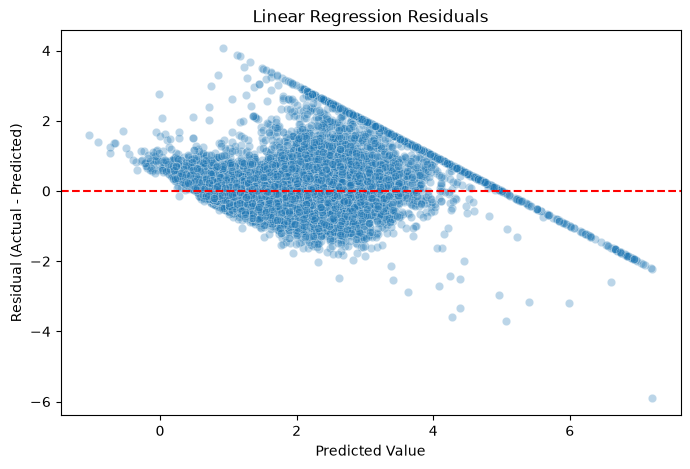

In [63]:
import matplotlib.pyplot
residuals = y_train - y_pred

fig, ax = plt.subplots(figsize=(8, 5))

sns.scatterplot(
    x=y_pred,
    y=residuals,
    alpha=0.3,
    ax=ax
)

ax.axhline(0, color="red", linestyle="--")

ax.set_xlabel("Predicted Value")
ax.set_ylabel("Residual (Actual - Predicted)")
ax.set_title("Linear Regression Residuals")

plt.show()

In [64]:
np.mean(y_train-y_pred)

np.float64(7.322845746377427e-12)

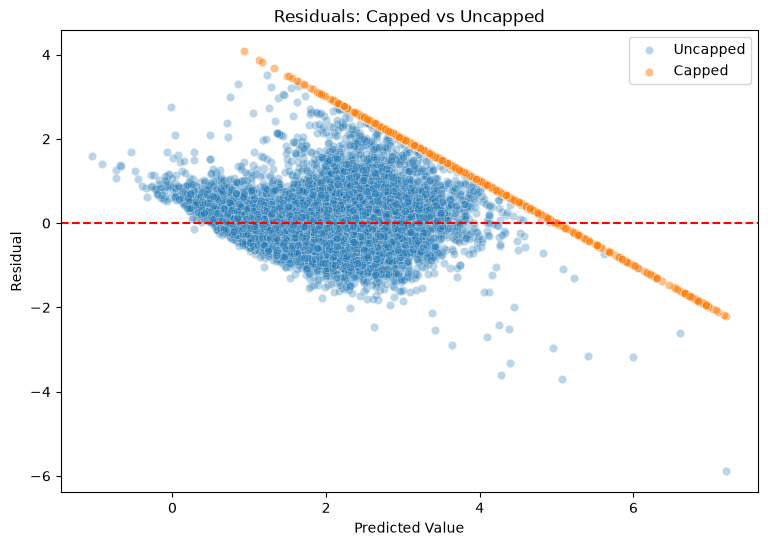

In [65]:
import matplotlib.pyplot as plt
import seaborn as sns

residuals = y_train - y_pred

capped = y_train >= 5

fig, ax = plt.subplots(figsize=(9, 6))

sns.scatterplot(
    x=y_pred[~capped],
    y=residuals[~capped],
    alpha=0.3,
    label="Uncapped",
    ax=ax
)

sns.scatterplot(
    x=y_pred[capped],
    y=residuals[capped],
    alpha=0.5,
    label="Capped",
    ax=ax
)

ax.axhline(0, color="red", linestyle="--")

ax.set_xlabel("Predicted Value")
ax.set_ylabel("Residual")
ax.set_title("Residuals: Capped vs Uncapped")

plt.show()

In [66]:
# Create a diagnostic dataframe
diagnostics = df_train.copy()

diagnostics["actual"] = y_train
diagnostics["predicted"] = y_pred
diagnostics["residual"] = y_train - y_pred

# Examine the 10 largest absolute errors
diagnostics["abs_error"] = diagnostics["residual"].abs()

diagnostics.sort_values(
    "abs_error",
    ascending=False
).head(10)

,index,medinc,houseage,averooms,avebedrms,population,aveoccup,latitude,longitude,actual,predicted,residual,abs_error
6688,16040,3.5156,42.0,4.794621,1.044010,1211.0,2.960880,37.71,-122.47,5.00001,2.481000,4.074064,4.074064
10574,18574,2.5599,42.0,2.826446,0.966942,2312.0,4.776860,36.91,-121.75,5.00001,2.278228,3.873144,3.873144
10448,10307,7.5744,25.0,6.932927,1.036585,524.0,3.195122,33.90,-117.82,5.00001,3.391044,3.834992,3.834992
4548,19374,2.2024,20.0,5.277778,1.037037,304.0,2.814815,37.76,-120.90,0.67500,0.884210,-3.596065,3.596065
1633,14817,6.3612,35.0,7.038554,1.055422,1042.0,2.510843,32.69,-117.19,4.75000,3.188676,3.524267,3.524267
10454,10713,4.5833,5.0,3.888889,1.000000,384.0,2.245614,33.66,-117.84,5.00001,2.354903,3.503446,3.503446
6639,10695,3.7422,16.0,5.042125,1.054945,857.0,1.569597,33.61,-117.74,5.00001,1.955587,3.485388,3.485388
6651,20286,3.5867,32.0,5.087662,0.987013,1482.0,4.811688,34.17,-119.17,5.00001,2.371466,3.382035,3.382035
9850,12893,2.6266,23.0,4.768031,1.019493,1132.0,2.206628,38.65,-121.33,5.00000,0.967831,3.293841,3.293841
4259,14922,4.7068,6.0,5.810320,1.059593,4771.0,3.467297,32.62,-116.98,5.00001,2.272252,3.285020,3.285020


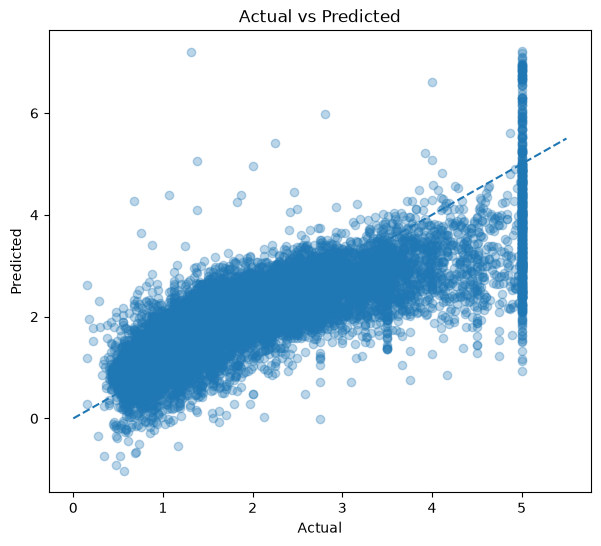

In [67]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_train, y_pred, alpha=0.3)
ax.plot([0, 5.5], [0, 5.5], linestyle='--')
ax.set_xlabel("Actual")
ax.set_ylabel("Predicted")
ax.set_title("Actual vs Predicted")
plt.show()